# Evaluating Machine Learning Methods for Imbalanced Classification

## 1. Introduction

Machine learning classification techniques play an important role in healthcare data analysis, where predictive models can help identify patterns associated with medical conditions. However, when a dataset contains an unequal distribution of target classes, classification algorithms may become biased toward the majority class, potentially reducing their ability to identify minority-class observations.

This project presents a comparative evaluation of machine learning methods for imbalanced binary classification using the Pima Indians Diabetes Database. The main objective is to investigate how different classification algorithms perform under class imbalance and to assess the effect of class-weighting strategies on predictive performance.

Six classification models are implemented and evaluated: Logistic Regression, Balanced Logistic Regression, Decision Tree, Balanced Decision Tree, Random Forest, and Balanced Random Forest. The comparison provides insight into how different learning algorithms respond to class imbalance and how class weighting influences their classification behaviour.

The experimental workflow includes data inspection, preprocessing, stratified train-test splitting, model development, and performance evaluation. Five-fold stratified cross-validation is used to compare the models based on Accuracy, Precision, Recall, F1-score, and ROC-AUC. Additional ROC and Precision-Recall analyses, together with classification threshold evaluation, are used to examine model performance from complementary perspectives.

Through this comparative analysis, the project aims to identify the trade-offs between predictive accuracy and minority-class detection, highlighting the importance of selecting appropriate evaluation metrics and classification strategies for imbalanced healthcare datasets.

## 2. Dataset Description

This project uses the Pima Indians Diabetes Database, a dataset commonly used in machine learning research and educational studies involving binary classification. It contains 768 observations and 9 columns, including 8 predictor features and one target variable.

The predictor features describe several health-related measurements and demographic characteristics, including the number of pregnancies, glucose concentration, blood pressure, skin thickness, insulin level, body mass index (BMI), diabetes pedigree function, and age.

The target variable, `Outcome`, indicates the diabetes classification:
	•	0: Non-diabetic
	•	1: Diabetic

The dataset contains 500 observations in class 0 (65.1%) and 268 observations in class 1 (34.9%). This distribution indicates a moderate class imbalance, with the non-diabetic class representing the majority of observations.

Because the target classes are not equally represented, this dataset provides an appropriate setting for comparing classification algorithms and examining how class-weighting strategies influence model performance, particularly in identifying observations belonging to the minority class.

## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was conducted to gain an initial understanding of the dataset, examine the distribution of its features, and identify potential data quality issues before model development.

The analysis included examining the dataset’s structure, calculating descriptive statistics, and exploring the distribution of the target variable (`Outcome`). Visualizations were also used to better understand the characteristics and distribution of the predictor features.

Particular attention was given to zero values in selected medical measurement features, including `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`. Although the original dataset contains no explicitly recorded missing values, zero values in these features may represent missing or invalid measurements rather than meaningful observations.

Identifying these values was important for making informed preprocessing decisions and preparing the dataset for subsequent machine learning experiments.

## 3.1 Dataset Structure and Overview

The initial inspection of the dataset was performed to understand its overall structure and verify the characteristics of the available data before proceeding with exploratory analysis and preprocessing.

The dataset consists of 768 observations and 9 columns, including 8 predictor features and one target variable (`Outcome`). The features contain numerical information related to health measurements and demographic characteristics.

Several inspection methods were used to examine the dataset:
	•	`df.shape` was used to determine the number of rows and columns.
	•	`df.info()` was used to inspect column names, data types, and non-null counts.
	•	`df.describe()` was used to generate descriptive statistics, including the mean, standard deviation, minimum, maximum, and quartile values of the numerical features.

The initial inspection confirmed that all columns contain numerical data and that no explicitly recorded missing values were present in the original dataset. However, further examination was necessary to identify zero values that could represent missing or invalid measurements in selected medical features.

These initial observations provided a foundation for the subsequent exploratory analysis and data preprocessing stages.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [2]:
url="https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = ["Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df =pd.read_csv(url,names=columns)


In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [7]:
df["Outcome"].value_counts(normalize=True) * 100

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

## 3.2 Target Variable Distribution

The distribution of the target variable (`Outcome`) was examined to assess the class balance in the dataset. The results show that 500 observations (65.1%) belong to class 0, representing non-diabetic individuals, while 268 observations (34.9%) belong to class 1, representing diabetic individuals.

This distribution indicates a moderate class imbalance, with class 0 being the majority class and class 1 being the minority class. This imbalance is important because classification models may become biased toward the majority class, potentially reducing their ability to correctly identify minority-class observations.

Therefore, this dataset provides an opportunity to investigate the effect of class-weighting strategies on model performance, particularly in terms of minority-class detection.

In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 3.3 Descriptive Statistics

Descriptive statistics were calculated to summarize the numerical characteristics of the dataset. The results provide information about the central tendency, variability, and range of each feature.

The dataset contains 768 observations, and all columns have 768 non-null values. However, the minimum values of several medical measurement features, including `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BM`I, are zero.

Although the original dataset contains no explicitly recorded missing values, these zero values may represent missing or invalid measurements. Therefore, they require further investigation before preprocessing.

The descriptive statistics also show differences in the scale and variability of the predictor features, which will be considered during the preprocessing stage.

In [10]:
columns_to_check = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
(df[columns_to_check] == 0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

## 3.4 Investigation of Zero Values

The dataset was examined for zero values in selected medical measurement features, including `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`.

The analysis identified 5 zero values in `Glucose`, 35 in `BloodPressure`, 227 in `SkinThicknes`s, 374 in `Insulin`, and 11 in `BMI`.

Zero values in these features may represent missing or invalid measurements rather than meaningful observations. This is particularly relevant for `Insulin` and `SkinThickness`, which contain a relatively large number of zero values.

These findings indicate that the dataset may contain implicit missing values, even though no explicitly recorded missing values were detected during the initial inspection. Therefore, the identified zero values will be considered during the preprocessing stage, where an appropriate strategy for handling them will be applied.

In [11]:
df_clean = df.copy()
columns_to_replace = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]
df_clean[columns_to_replace] = df_clean[columns_to_replace].replace(0, np.nan)

In [12]:
df_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

## 3.5 Handling Invalid Zero Values

Based on the previous investigation, zero values in selected medical measurement features were treated as potentially missing or invalid observations. To preserve the original dataset, a separate copy named `df_clean` was created.

Zero values in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` were replaced with `NaN`. This allows these observations to be handled appropriately during the subsequent imputation stage.

The missing-value check confirmed that the replacement was performed successfully. The resulting dataset contains 5 missing values in `Glucose`, 35 in `BloodPressure`, 227 in `SkinThickness`, 374 in `Insulin`, and 11 in `BMI`. The remaining columns contain no missing values.

The original `df` dataset was preserved, while `df_clean` will be used for the subsequent preprocessing steps.

In [13]:
X = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)


In [14]:
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [15]:
y.head()

0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

In [16]:
imputer = SimpleImputer(strategy ="median")

In [17]:
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
print("Missing values in training data :",np.isnan(X_train_imputed).sum())
print("Missing values in test data :",np.isnan(X_test_imputed).sum())
      

Missing values in training data : 0
Missing values in test data : 0


In [18]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train_imputed,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [19]:
y_pred = model.predict(X_test_imputed)
print(y_pred[:10])

[1 0 0 0 0 0 0 1 0 1]


In [20]:
comparison = pd.DataFrame({
    "Actual":y_test.values[:10],
    "Prediction":y_pred[:10]
})
print(comparison)

   Actual  Prediction
0       0           1
1       0           0
2       0           0
3       1           0
4       0           0
5       0           0
6       1           0
7       1           1
8       0           0
9       0           1


In [21]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy percentage :",accuracy*100,"%")

Accuracy percentage : 70.12987012987013 %


In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



In [23]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[81 19]
 [27 27]]


In [24]:
model_balanced = LogisticRegression(max_iter = 1000,class_weight ="balanced")
model_balanced.fit(X_train_imputed,y_train)
y_pred_balanced = model_balanced.predict(X_test_imputed)

In [25]:
accuracy_balanced = accuracy_score(y_test,y_pred_balanced)
print("Balanced model accuracy:",accuracy*100,"%")

print("clasiification report Balanced model :",classification_report(y_test,y_pred_balanced))

cm_balanced = confusion_matrix(y_test,y_pred_balanced)
print("confusion matrix:",cm_balanced)


Balanced model accuracy: 70.12987012987013 %
clasiification report Balanced model :               precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

confusion matrix: [[75 25]
 [16 38]]


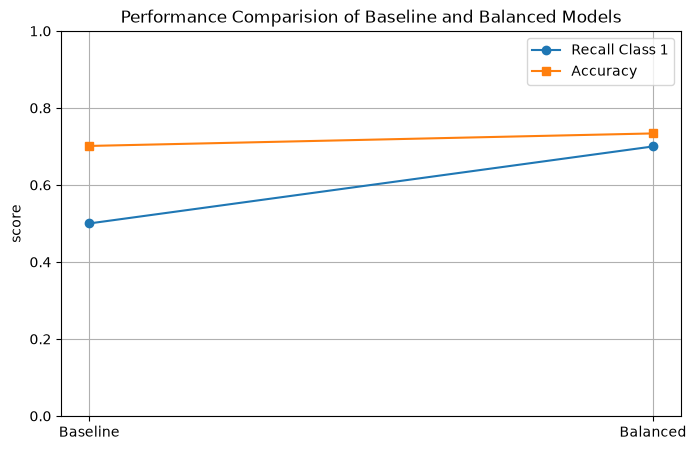

In [26]:
models =["Baseline","Balanced"]

recall_class_1 =[0.50,0.70]
accuracy=[0.7013,0.7338]

plt.figure(figsize=(8,5))

plt.plot(models,recall_class_1,marker="o",label="Recall Class 1")
plt.plot(models,accuracy,marker="s",label="Accuracy")

plt.title("Performance Comparision of Baseline and Balanced Models")
plt.ylabel("score")
plt.ylim(0,1)

plt.legend()
plt.grid(True)

plt.show()




## 3.6 Comparison of Baseline and Balanced Logistic Regression

Two Logistic Regression models were developed and evaluated to investigate the effect of class weighting on imbalanced classification. The first model used the default class weights, while the second model applied the `balanced` class-weighting strategy.

The results showed that the balanced model achieved a higher accuracy (73.38%) than the baseline model (70.13%). More importantly, the recall for the positive class (`Outcome` = 1) increased from 0.50 to 0.70, indicating an improvement in identifying patients with diabetes.

The confusion matrices showed that false negatives decreased from 27 to 16, while false positives increased from 19 to 25. This demonstrates a trade-off between identifying more positive cases and producing more false-positive predictions.

Overall, class weighting improved the detection of the positive class in this experiment. However, these results are based on a single train-test split and should be interpreted as preliminary findings. Further evaluation using cross-validation and additional classification algorithms is necessary before drawing final conclusions.

## 3.7 Cross-Validation Evaluation

To obtain a more reliable estimate of model performance, stratified 5-fold cross-validation was selected. Unlike a single train-test split, cross-validation evaluates a model across multiple data partitions, providing a broader assessment of its performance.

Stratified sampling was used to preserve the approximate proportion of diabetic and non-diabetic cases in each fold. This is particularly important for the present dataset because the target variable is moderately imbalanced.

To prevent data leakage during cross-validation, preprocessing steps will be incorporated into machine learning pipelines. This ensures that imputation and feature scaling are fitted separately within each training fold rather than using information from the validation fold.

The cross-validation procedure will be applied to the training data, while the test set will remain separate for the final evaluation of the selected models.

In [27]:
from sklearn.model_selection import StratifiedKFold,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [28]:
baseline_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("Scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=1000))
                             ])


balanced_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("Scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=1000,class_weight="balanced"))
                             ])                       

In [29]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy" : "accuracy",
    "precision" : "precision",
    "recall" : "recall",
    "f1" : "f1"
}
baseline_scores = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)


In [30]:
print("Baseline Model Results")

for metric in scoring.keys():
    scores = baseline_scores["test_" + metric]

    print(metric,":",scores)
    print("Mean:",scores.mean())
    print("Standard Deviation:",scores.std())

Baseline Model Results
accuracy : [0.78861789 0.78861789 0.82113821 0.7804878  0.76229508]
Mean: 0.7882313741170198
Standard Deviation: 0.019056824693417025
precision : [0.79310345 0.74285714 0.86206897 0.73529412 0.68571429]
Mean: 0.7638075920023182
Standard Deviation: 0.05977298511205282
recall : [0.53488372 0.60465116 0.58139535 0.58139535 0.57142857]
Mean: 0.5747508305647842
Standard Deviation: 0.022727749337524358
f1 : [0.63888889 0.66666667 0.69444444 0.64935065 0.62337662]
Mean: 0.6545454545454545
Standard Deviation: 0.024423199069116826


In [31]:
balanced_scores = cross_validate(
    balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Balanced Model Results")
for metric in scoring.keys():
    scores = balanced_scores["test_" + metric]

    print(metric,":",scores)
    print("Mean:",scores.mean())
    print("Standard Deviation:",scores.std())



Balanced Model Results
accuracy : [0.7804878  0.74796748 0.76422764 0.76422764 0.75409836]
Mean: 0.7622017859522857
Standard Deviation: 0.01105321358323955
precision : [0.68181818 0.61538462 0.675      0.64583333 0.625     ]
Mean: 0.6486072261072261
Standard Deviation: 0.026337363428464235
recall : [0.69767442 0.74418605 0.62790698 0.72093023 0.71428571]
Mean: 0.7009966777408638
Standard Deviation: 0.039477610039901516
f1 : [0.68965517 0.67368421 0.65060241 0.68131868 0.66666667]
Mean: 0.6723854281128022
Standard Deviation: 0.01331869395358905


In [32]:
f1_comparison = pd.DataFrame({
    "Baseline_F1":baseline_scores["test_f1"],
    "Balanced_F1":balanced_scores["test_f1"]
})
comparison["Difference"] = (
    f1_comparison["Balanced_F1"]  - f1_comparison["Baseline_F1"]
        )
print(f1_comparison)

   Baseline_F1  Balanced_F1
0     0.638889     0.689655
1     0.666667     0.673684
2     0.694444     0.650602
3     0.649351     0.681319
4     0.623377     0.666667


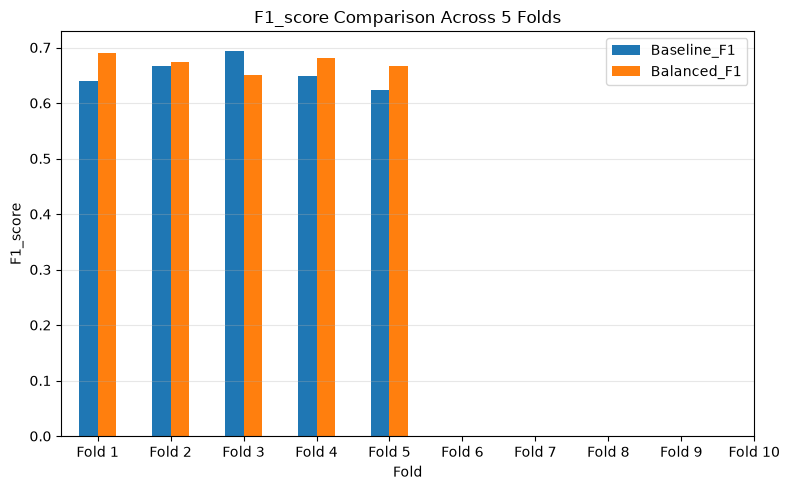

In [33]:
f1_comparison[["Baseline_F1","Balanced_F1"]].plot(
    kind = "bar",
    figsize =(8,5)
)
plt.xlabel("Fold")
plt.ylabel("F1_score")
plt.title("F1_score Comparison Across 5 Folds")

plt.xticks(
    ticks=range(len(comparison)),
    labels=[f"Fold {i+1}" for i in range(len(comparison))],
    rotation = 0
)

plt.legend()
plt.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()
    

## 3.8 Cross-Validation Results and Discussion

Five-fold stratified cross-validation was performed to evaluate the baseline and balanced Logistic Regression models using the training dataset. This approach provided a more comprehensive assessment of model performance than a single train-test split.

The baseline model achieved a mean accuracy of 78.82% and a mean precision of 76.38%. However, its mean recall was 57.48%, indicating that it did not identify a substantial proportion of positive cases.

The balanced model achieved a lower mean accuracy of 76.22% and a lower mean precision of 64.86%. However, its mean recall increased to 70.10%, while its mean F1-score improved from 65.45% to 67.24%.

The fold-by-fold comparison also showed that the balanced model achieved a higher F1-score in four out of the five folds. This suggests that class weighting improved the balance between precision and recall across most validation folds.

Overall, the results indicate that class weighting improved the identification of positive cases, although this improvement came with a reduction in accuracy and precision. The choice between the two models therefore depends on the relative importance of identifying positive cases and limiting false-positive predictions.

These findings are based on cross-validation within the training dataset. The independent test set will be retained for the final evaluation of the models.

In [34]:
baseline_pipeline.fit(X_train,y_train)
balanced_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('Scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For str

In [35]:
y_probability_baseline = baseline_pipeline.predict_proba(X_test)[:, 1]
y_probability_balanced = balanced_pipeline.predict_proba(X_test)[:, 1]

In [36]:
from sklearn.metrics import roc_auc_score
roc_auc_baseline = roc_auc_score(
    y_test,
    y_probability_baseline
)

roc_auc_balanced = roc_auc_score(
    y_test,
    y_probability_balanced
)

print(" Baseline ROC_AUC:",roc_auc_baseline)

print(" Balanced ROC_AUC:",roc_auc_balanced)

 Baseline ROC_AUC: 0.812962962962963
 Balanced ROC_AUC: 0.8125925925925926


### 3.9 ROC-AUC Evaluation

The ROC-AUC metric was calculated for both Logistic Regression models using the independent test dataset. This metric evaluates the ability of a classifier to distinguish between positive and negative classes across different classification thresholds.

The baseline Logistic Regression model achieved a ROC-AUC score of 0.8130, while the balanced Logistic Regression model achieved a score of 0.8126.

The results indicate that both models have very similar discriminative performance. Although the baseline model obtained a slightly higher ROC-AUC score, the difference between the two models was negligible.

These findings suggest that applying class weighting improved the recall of the positive class during cross-validation, but did not produce a noticeable improvement in the overall ranking ability of the model.

Overall, ROC-AUC provides an additional perspective on model performance and complements metrics such as accuracy, precision, recall, and F1-score. Since the results are based on a single test split, further evaluation would be required to assess the stability of these findings.

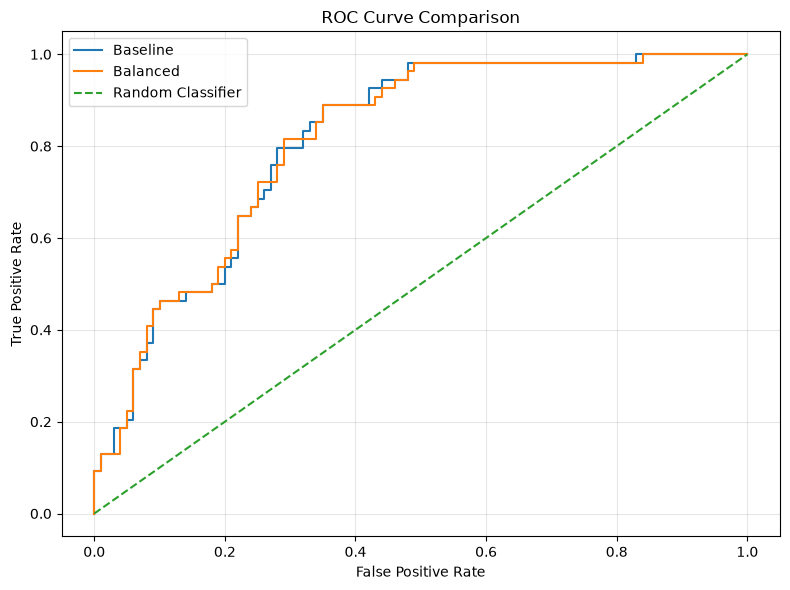

In [37]:
from sklearn.metrics import roc_curve

fpr_baseline,tpr_baseline, _ = roc_curve(
   y_test,y_probability_baseline
)
fpr_balanced,tpr_balanced, _=roc_curve(
    y_test,y_probability_balanced
)
plt.figure(figsize=(8,6))

plt.plot(fpr_baseline,tpr_baseline,label="Baseline")
plt.plot(fpr_balanced,tpr_balanced,label="Balanced")

plt.plot([0,1],[0,1],linestyle="--",label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
    

### 3.10 ROC Curve Comparison

The Receiver Operating Characteristic (ROC) curves were plotted to compare the classification performance of the baseline and balanced Logistic Regression models across different classification thresholds.

The ROC curve illustrates the relationship between the True Positive Rate (TPR) and the False Positive Rate (FPR). A curve closer to the upper-left corner generally indicates better classification performance, while the diagonal line represents the performance of a random classifier.

The two ROC curves show very similar patterns, which is consistent with the ROC-AUC scores obtained previously. The baseline model achieved a ROC-AUC of 0.8130, while the balanced model achieved 0.8126.

These results indicate that applying class weighting did not substantially change the overall ability of the models to distinguish between the two classes. However, the balanced model demonstrated a higher recall for the positive class during cross-validation.

Overall, the ROC curve provides a visual comparison of model performance across different decision thresholds and complements the numerical evaluation metrics.

In [38]:
from sklearn.metrics import precision_recall_curve,average_precision_score

precision_baseline,recall_baseline, _ = precision_recall_curve(
    y_test,y_probability_baseline
)
precision_balanced,recall_balanced,_ = precision_recall_curve(
    y_test,y_probability_balanced
)


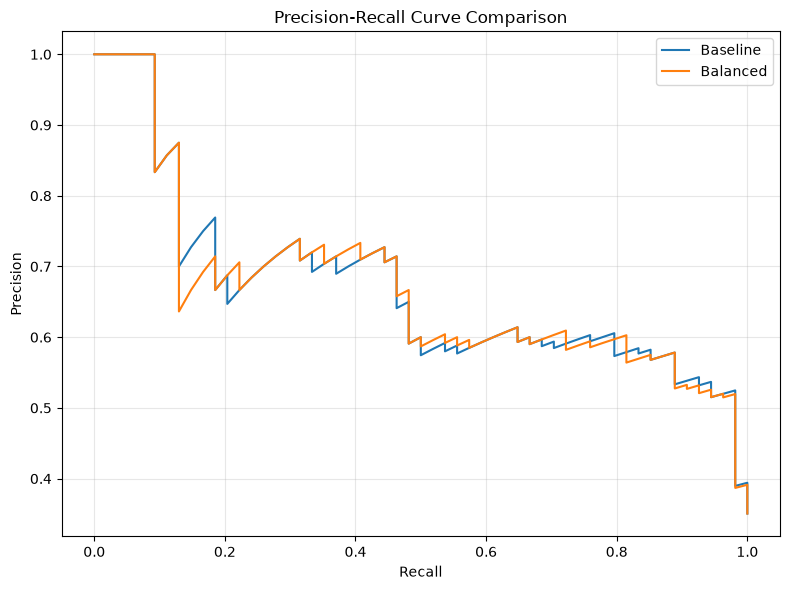

In [39]:
plt.figure(figsize=(8,6))

plt.plot(recall_baseline,precision_baseline,label="Baseline")
plt.plot(recall_balanced,precision_balanced,label="Balanced")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
ap_baseline = average_precision_score(
    y_test, y_probability_baseline
)
ap_balanced = average_precision_score(
    y_test, y_probability_balanced
)

print("Baseline Average Precision:", ap_baseline)
print("Balanced Average Precision:", ap_balanced)

Baseline Average Precision: 0.673326163579994
Balanced Average Precision: 0.6726594107811763


In [41]:
from sklearn.metrics import balanced_accuracy_score

y_pred_baseline_pipeline = baseline_pipeline.predict(X_test)
y_pred_balanced_pipeline = balanced_pipeline.predict(X_test)

ba_baseline = balanced_accuracy_score(
    y_test,y_pred_baseline_pipeline
)
ba_balanced = balanced_accuracy_score(
    y_test,y_pred_balanced_pipeline
)

print("Baseline Balanced Accuracy :",ba_baseline)
print("Balanced Balanced Accuracy :",ba_balanced)

Baseline Balanced Accuracy : 0.6599999999999999
Balanced Balanced Accuracy : 0.7268518518518519


In [42]:
from sklearn.metrics import precision_score,recall_score,f1_score

thresholds = [0.3,0.4,0.5,0.6,0.7]

results = []

for model_name,probabilities in [
    ("Baseline",y_probability_baseline),
    ("Balanced",y_probability_balanced)
]:
    for threshold in thresholds:
        predictions =(probabilities >= threshold).astype(int)

        results.append({
            "Model": model_name,
            "Threshold":threshold,
            "Precision": precision_score(y_test,predictions),
            "Recall": recall_score(y_test,predictions),
            "F1":f1_score(y_test,predictions)
        })
threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))


      Model  Threshold  Precision  Recall     F1
0  Baseline        0.3      0.597   0.796  0.683
1  Baseline        0.4      0.614   0.648  0.631
2  Baseline        0.5      0.600   0.500  0.545
3  Baseline        0.6      0.641   0.463  0.538
4  Baseline        0.7      0.714   0.370  0.488
5  Balanced        0.3      0.545   0.889  0.676
6  Balanced        0.4      0.570   0.833  0.677
7  Balanced        0.5      0.603   0.704  0.650
8  Balanced        0.6      0.596   0.574  0.585
9  Balanced        0.7      0.619   0.481  0.542


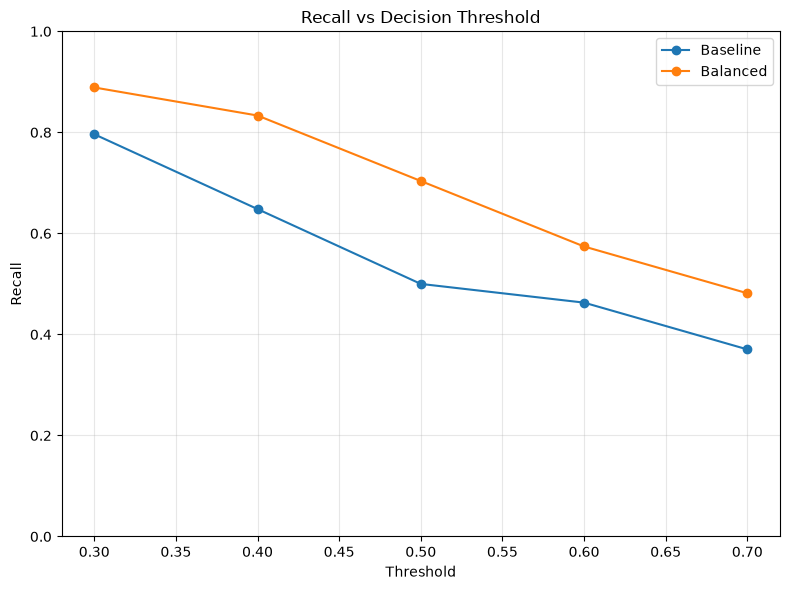

In [43]:
plt.figure(figsize=(8,6))

for model_name in ["Baseline","Balanced"]:
    subset = threshold_results[
        threshold_results["Model"] == model_name
    ]
    plt.plot(
        subset["Threshold"],
        subset["Recall"],
        marker="o",
        label=model_name
    )
plt.xlabel("Threshold")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.title("Recall vs Decision Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

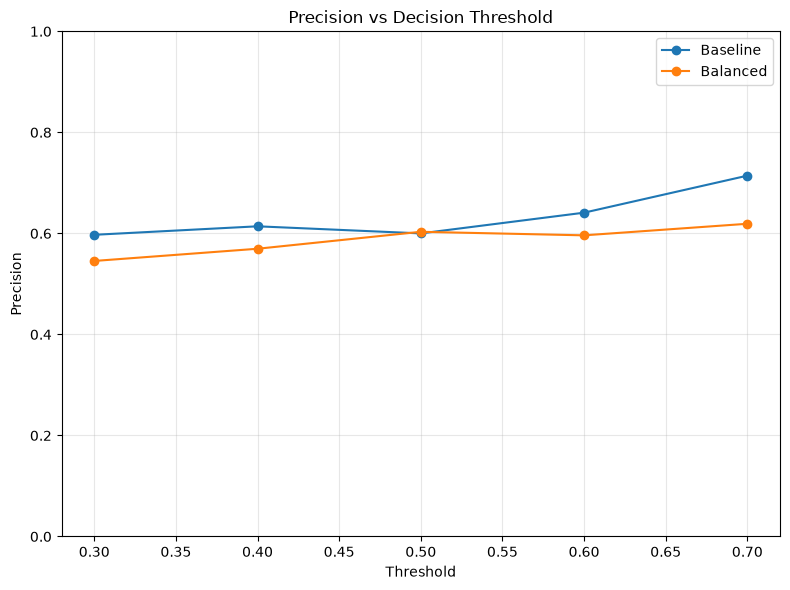

In [44]:
plt.figure(figsize=(8, 6))

for model_name in ["Baseline", "Balanced"]:
    subset = threshold_results[
        threshold_results["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["Precision"],
        marker="o",
        label=model_name
    )

plt.xlabel("Threshold")
plt.ylabel("Precision")
plt.ylim(0, 1)
plt.title("Precision vs Decision Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

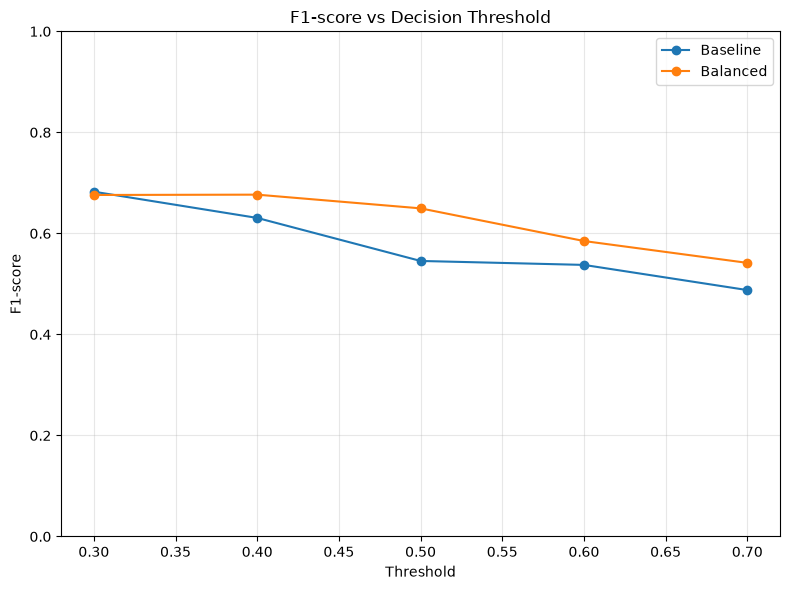

In [45]:
plt.figure(figsize=(8, 6))

for model_name in ["Baseline", "Balanced"]:
    subset = threshold_results[
        threshold_results["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["F1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.title("F1-score vs Decision Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.11 Decision Threshold Analysis

The effect of different classification thresholds on model performance was investigated for both the baseline and balanced Logistic Regression models.

Threshold values ranging from 0.3 to 0.7 were examined to evaluate changes in precision, recall, and F1-score. The results demonstrated that lowering the classification threshold generally increased recall, while increasing the threshold tended to improve precision.

The baseline model achieved its highest F1-score of 0.683 at a threshold of 0.3, whereas the balanced model achieved its highest F1-score of 0.677 at a threshold of 0.4.

The three plots illustrate how precision, recall, and F1-score change as the decision threshold varies. These visualizations highlight the trade-off between identifying positive cases and limiting false-positive predictions.

It is important to note that this threshold analysis was conducted on the test dataset for exploratory purposes. Therefore, the observed thresholds should not be considered final model-selection decisions. A separate validation procedure would be required to select an appropriate threshold without compromising the independence of the test dataset.

### 4. Decision Tree Classification

To further investigate the performance of machine learning algorithms on the diabetes dataset, Decision Tree classification was selected as the next model.

Unlike Logistic Regression, which models the relationship between features and the target using a linear decision function, a Decision Tree uses a sequence of rule-based decisions to classify observations.

Decision Trees can capture nonlinear relationships and interactions between features. However, they may be prone to overfitting, particularly when their complexity is not controlled.

In this section, both standard and class-weighted Decision Tree models will be developed and evaluated. Their performance will be compared using stratified cross-validation and appropriate classification metrics.

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

tree_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("model",DecisionTreeClassifier(random_state=42))
])


In [47]:
tree_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or

In [48]:
y_pred_tree=tree_pipeline.predict(X_test)

In [49]:
from sklearn.metrics import classification_report,confusion_matrix

print("Classification Report:")
print(classification_report(y_test,y_pred_tree))

print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred_tree))


Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.76       100
           1       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154

Confusion Matrix:
[[79 21]
 [28 26]]


### 4.1 Decision Tree Results and Discussion

The Decision Tree model was evaluated on the independent test dataset using a classification report and a confusion matrix.

The model achieved an accuracy of 68.18%. For the positive class (Outcome = 1), the model obtained a precision of 0.55, a recall of 0.48, and an F1-score of 0.51.

The confusion matrix showed that the model correctly identified 26 positive cases and 79 negative cases. However, it misclassified 28 positive cases as negative (false negatives) and 21 negative cases as positive (false positives).

The relatively low recall for the positive class indicates that the Decision Tree model failed to identify more than half of the actual diabetes cases in the test dataset. This is an important limitation when evaluating classification models on medical datasets.

Overall, the initial Decision Tree model showed limited performance in identifying positive cases. Further evaluation using a class-weighted Decision Tree model will help investigate whether adjusting the class weights can improve the detection of the minority class.

In [50]:
tree_balanced_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

In [51]:
tree_balanced_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or

In [52]:
y_pred_tree_balanced = tree_balanced_pipeline.predict(X_test)

In [53]:
print("Classification Report:")
print(classification_report(y_test, y_pred_tree_balanced))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree_balanced))

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.84      0.79       100
           1       0.62      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

Confusion Matrix:
[[84 16]
 [28 26]]


### 4.2 Balanced Decision Tree Results and Discussion

The class-weighted Decision Tree model was evaluated on the independent test dataset using a classification report and a confusion matrix.

The model achieved an accuracy of 71.43%. For the positive class (Outcome = 1), it obtained a precision of 0.62, a recall of 0.48, and an F1-score of 0.54.

The confusion matrix showed that the model correctly identified 26 positive cases and 84 negative cases. It misclassified 28 positive cases as negative (false negatives) and 16 negative cases as positive (false positives).

Compared with the standard Decision Tree model, the balanced model achieved higher accuracy, precision, and F1-score. However, recall for the positive class remained unchanged at 0.48, indicating that class weighting did not improve the detection of additional positive cases in this test evaluation.

Overall, class weighting reduced the number of false-positive predictions but did not improve the identification of positive cases. Further evaluation with other classification algorithms is therefore necessary.

In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])

In [55]:
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or

In [56]:
y_pred_rf = rf_pipeline.predict(X_test)

In [57]:
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.59      0.64        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.73       154
weighted avg       0.76      0.77      0.76       154

Confusion Matrix:
[[86 14]
 [22 32]]


### 4.3 Random Forest Results and Discussion

The Random Forest model was evaluated on the independent test dataset using a classification report and a confusion matrix.

The model achieved an accuracy of 77.27%. For the positive class (Outcome = 1), it obtained a precision of 0.70, a recall of 0.59, and an F1-score of 0.64.

The confusion matrix showed that the model correctly identified 32 positive cases and 86 negative cases. It misclassified 22 positive cases as negative (false negatives) and 14 negative cases as positive (false positives).

Compared with the Decision Tree models, Random Forest achieved higher accuracy, precision, recall, and F1-score for the positive class. These results suggest that combining multiple decision trees improved classification performance in this experiment.

However, the model still failed to identify 22 of the 54 actual positive cases. Therefore, further evaluation is necessary to investigate whether class weighting or additional model optimization can improve the detection of positive cases.

Overall, Random Forest demonstrated promising performance compared with the previously evaluated models. Its performance will also be examined using stratified cross-validation to obtain a more reliable assessment.

In [58]:
rf_balanced_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

In [59]:
rf_balanced_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or

In [60]:
y_pred_rf_balanced = rf_balanced_pipeline.predict(X_test)

In [61]:
print("Classification Report:")
print(classification_report(y_test, y_pred_rf_balanced))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_balanced))

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.80      0.81       100
           1       0.64      0.67      0.65        54

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.76      0.75      0.75       154

Confusion Matrix:
[[80 20]
 [18 36]]


### 4.4 Balanced Random Forest Results and Discussion

The class-weighted Random Forest model was evaluated on the independent test dataset using a classification report and a confusion matrix.

The model achieved an accuracy of 75.32%. For the positive class (Outcome = 1), it obtained a precision of 0.64, a recall of 0.67, and an F1-score of 0.65.

The confusion matrix showed that the model correctly identified 36 positive cases and 80 negative cases. It misclassified 18 positive cases as negative (false negatives) and 20 negative cases as positive (false positives).

Compared with the standard Random Forest model, the balanced version achieved a higher recall and F1-score for the positive class. Recall increased from 0.59 to 0.67, while the number of false negatives decreased from 22 to 18.

However, this improvement came with a reduction in accuracy and precision, as well as an increase in false-positive predictions.

Overall, class weighting improved the identification of positive cases in the test evaluation, although it introduced a trade-off between recall and precision. Further evaluation using stratified cross-validation is necessary to assess the consistency of these results.

In [62]:
models = {
    "Logistic Regression": baseline_pipeline,
    "Balanced Logistic Regression": balanced_pipeline,
    "Decision Tree": tree_pipeline,
    "Balanced Decision Tree": tree_balanced_pipeline,
    "Random Forest": rf_pipeline,
    "Balanced Random Forest": rf_balanced_pipeline
}

In [63]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [64]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [65]:
from sklearn.model_selection import cross_validate

cv_results = {}

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results[model_name] = scores

In [66]:
summary = []

for model_name, scores in cv_results.items():
    summary.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_summary = pd.DataFrame(summary)

print(cv_summary.round(3))

                          Model  Accuracy  Precision  Recall     F1  ROC-AUC
0           Logistic Regression     0.788      0.764   0.575  0.655    0.843
1  Balanced Logistic Regression     0.762      0.649   0.701  0.672    0.844
2                 Decision Tree     0.673      0.531   0.580  0.552    0.651
3        Balanced Decision Tree     0.673      0.532   0.533  0.532    0.640
4                 Random Forest     0.761      0.690   0.575  0.626    0.816
5        Balanced Random Forest     0.764      0.654   0.701  0.675    0.820


### 4.5 Cross-Validation Comparison of All Models

Stratified five-fold cross-validation was performed to compare the performance of six classification models, including standard and class-weighted versions of Logistic Regression, Decision Tree, and Random Forest.

The results showed that the baseline Logistic Regression model achieved the highest mean accuracy (0.788) and precision (0.764). It also obtained a ROC-AUC score of 0.843.

The balanced Logistic Regression model achieved a higher mean recall (0.701) and F1-score (0.672) than its standard counterpart. It also achieved a slightly higher ROC-AUC score of 0.844.

Similarly, the balanced Random Forest model achieved a mean recall of 0.701 and the highest mean F1-score (0.675) among the evaluated models.

In contrast, the Decision Tree models demonstrated lower overall performance, with mean F1-scores of 0.552 and 0.532 for the standard and balanced versions, respectively.

The results indicate that class weighting improved recall for Logistic Regression and Random Forest, although this improvement was accompanied by lower precision and accuracy. The ROC-AUC scores of the Logistic Regression models were very similar, suggesting that class weighting had little effect on their overall ranking ability.

Overall, the cross-validation results highlight the trade-offs between different classification metrics. The baseline Logistic Regression model performed well in terms of accuracy and precision, while the balanced Random Forest model achieved the highest mean F1-score. The final model selection will require consideration of the project’s evaluation priorities and further assessment on the independent test dataset.

### 4.6 Cross-Validation Variability Analysis

In addition to comparing the mean cross-validation scores, the variability of each evaluation metric was examined using the standard deviation across the five folds.

The standard deviation provides an indication of how consistently each model performs across different subsets of the training data. A lower standard deviation suggests more stable performance, whereas a higher value indicates greater variation between folds.

The results showed that Balanced Logistic Regression had the lowest standard deviation for the F1-score (0.013), indicating relatively consistent F1 performance across the five folds. Balanced Random Forest achieved the lowest standard deviation for recall (0.010), suggesting stable positive-class detection across folds.

In contrast, Logistic Regression showed a higher standard deviation for precision (0.060), indicating greater variation in precision across the folds. Balanced Decision Tree also showed relatively high variability in F1-score (0.030).

Overall, examining both the mean scores and their standard deviations provides a more comprehensive understanding of model performance. This analysis highlights that model evaluation should consider not only predictive performance but also consistency across different data partitions.

In [67]:
std_summary = []

for model_name, scores in cv_results.items():
    std_summary.append({
        "Model": model_name,
        "Accuracy_std": scores["test_accuracy"].std(),
        "Precision_std": scores["test_precision"].std(),
        "Recall_std": scores["test_recall"].std(),
        "F1_std": scores["test_f1"].std(),
        "ROC-AUC_std": scores["test_roc_auc"].std()
    })

cv_std = pd.DataFrame(std_summary)

print(cv_std.round(3))

                          Model  Accuracy_std  Precision_std  Recall_std  \
0           Logistic Regression         0.019          0.060       0.023   
1  Balanced Logistic Regression         0.011          0.026       0.039   
2                 Decision Tree         0.023          0.037       0.050   
3        Balanced Decision Tree         0.029          0.041       0.022   
4                 Random Forest         0.019          0.042       0.038   
5        Balanced Random Forest         0.028          0.047       0.010   

   F1_std  ROC-AUC_std  
0   0.024        0.019  
1   0.013        0.016  
2   0.027        0.021  
3   0.030        0.026  
4   0.027        0.022  
5   0.022        0.027  


In [68]:
final_cv_table = cv_summary.merge(
    cv_std,
    on="Model"
)

print(final_cv_table.round(3))

                          Model  Accuracy  Precision  Recall     F1  ROC-AUC  \
0           Logistic Regression     0.788      0.764   0.575  0.655    0.843   
1  Balanced Logistic Regression     0.762      0.649   0.701  0.672    0.844   
2                 Decision Tree     0.673      0.531   0.580  0.552    0.651   
3        Balanced Decision Tree     0.673      0.532   0.533  0.532    0.640   
4                 Random Forest     0.761      0.690   0.575  0.626    0.816   
5        Balanced Random Forest     0.764      0.654   0.701  0.675    0.820   

   Accuracy_std  Precision_std  Recall_std  F1_std  ROC-AUC_std  
0         0.019          0.060       0.023   0.024        0.019  
1         0.011          0.026       0.039   0.013        0.016  
2         0.023          0.037       0.050   0.027        0.021  
3         0.029          0.041       0.022   0.030        0.026  
4         0.019          0.042       0.038   0.027        0.022  
5         0.028          0.047       0.010 

### 4.7 Visual Comparison of Model Performance

To provide a clearer comparison of the six classification models, a grouped bar chart was created using their mean cross-validation scores.

The chart presents five evaluation metrics: Accuracy, Precision, Recall, F1-score, and ROC-AUC. This visualization makes it easier to identify differences in model performance and examine the trade-offs between the evaluation metrics.

The results show that Logistic Regression achieved the highest mean Accuracy and Precision, whereas Balanced Logistic Regression and Balanced Random Forest achieved the highest mean Recall.

Balanced Random Forest obtained the highest mean F1-score, while Balanced Logistic Regression achieved the highest mean ROC-AUC. These findings highlight that model performance varies depending on the evaluation metric considered.

Overall, the visualization complements the numerical comparison and provides a more intuitive overview of the strengths and limitations of the evaluated models.

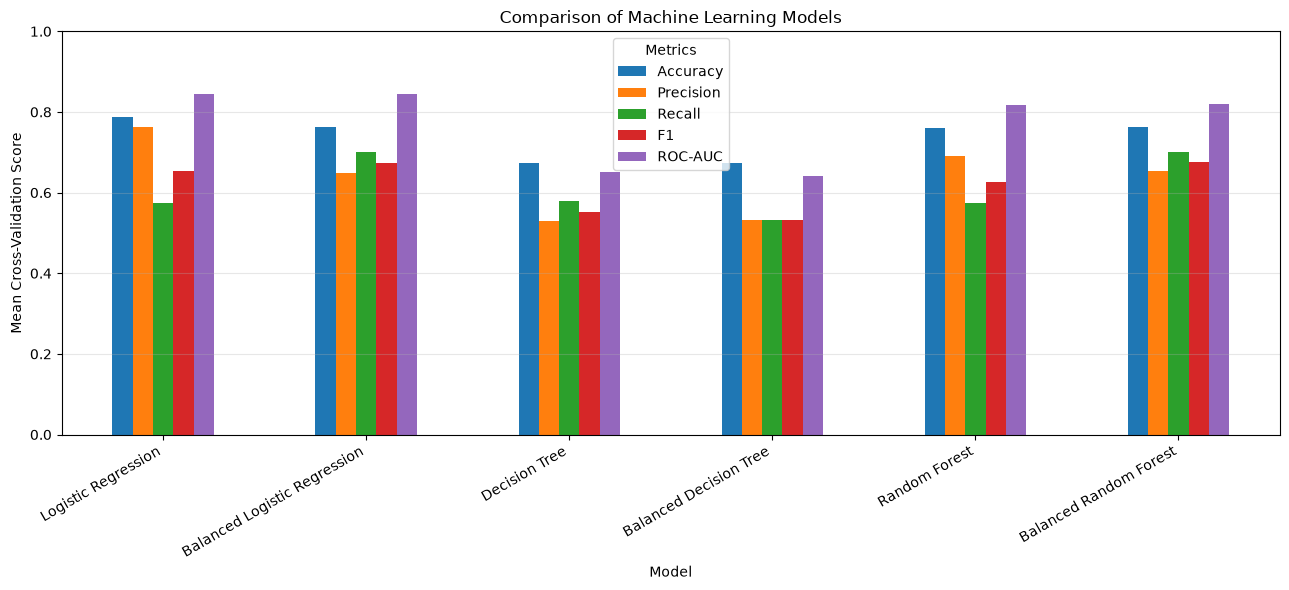

In [69]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

cv_summary.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Mean Cross-Validation Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.8 Final Cross-Validation Summary

A final summary table was prepared to present the mean and standard deviation of all evaluation metrics for the six classification models.

The table combines the results of the five-fold stratified cross-validation, providing a compact overview of both predictive performance and consistency across the folds.

The baseline Logistic Regression model achieved the highest mean Accuracy (0.788) and Precision (0.764). Balanced Logistic Regression achieved the highest mean ROC-AUC (0.844), while Balanced Random Forest obtained the highest mean Recall (0.701, shared with Balanced Logistic Regression) and F1-score (0.675).

These results demonstrate that different models offer different advantages depending on the evaluation metric. Therefore, model selection should consider the balance between predictive performance, positive-class detection, and consistency across cross-validation folds.

The final comparison provides a basis for selecting and further evaluating a suitable classification model for this imbalanced dataset.

final_report_table = cv_summary[["Model"]].copy()

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

for metric in metrics:
    final_report_table[metric] = [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(
            cv_summary[metric],
            cv_std[f"{metric}_std"]
        )
    ]

print(final_report_table.to_string(index=False))

In [70]:
final_report_table = cv_summary[["Model"]].copy()

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

for metric in metrics:
    final_report_table[metric] = [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(
            cv_summary[metric],
            cv_std[f"{metric}_std"]
        )
    ]

print(final_report_table.to_string(index=False))

                       Model      Accuracy     Precision        Recall            F1       ROC-AUC
         Logistic Regression 0.788 ± 0.019 0.764 ± 0.060 0.575 ± 0.023 0.655 ± 0.024 0.843 ± 0.019
Balanced Logistic Regression 0.762 ± 0.011 0.649 ± 0.026 0.701 ± 0.039 0.672 ± 0.013 0.844 ± 0.016
               Decision Tree 0.673 ± 0.023 0.531 ± 0.037 0.580 ± 0.050 0.552 ± 0.027 0.651 ± 0.021
      Balanced Decision Tree 0.673 ± 0.029 0.532 ± 0.041 0.533 ± 0.022 0.532 ± 0.030 0.640 ± 0.026
               Random Forest 0.761 ± 0.019 0.690 ± 0.042 0.575 ± 0.038 0.626 ± 0.027 0.816 ± 0.022
      Balanced Random Forest 0.764 ± 0.028 0.654 ± 0.047 0.701 ± 0.010 0.675 ± 0.022 0.820 ± 0.027


### 5. Feature Importance Analysis

After comparing the performance of the six classification models, Feature Importance Analysis was conducted to examine the relative contribution of input features to the predictions made by the Random Forest model.

Random Forest provides a feature importance measure based on the reduction in impurity across the decision trees in the ensemble. This measure helps identify which features contribute more to the model’s classification decisions.

In this section, the feature importance values of the standard Random Forest model will be extracted, ranked, and visualized to provide a better understanding of the role of different predictor variables.

It is important to note that feature importance reflects the model’s internal use of features and does not necessarily indicate a causal relationship or clinical significance.

In [71]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_pipeline.named_steps["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.to_string(index=False))

                 Feature  Importance
                 Glucose    0.272616
                     BMI    0.163688
DiabetesPedigreeFunction    0.124927
                     Age    0.113057
                 Insulin    0.089395
           BloodPressure    0.084337
             Pregnancies    0.080793
           SkinThickness    0.071187


### 5.1 Visualization of Feature Importance

To provide a clearer representation of the feature importance results, a horizontal bar chart was created to visualize the relative contribution of each predictor feature in the Random Forest model.

The features are displayed in descending order of importance, making it easier to identify which variables contribute most to the model’s predictions.

The visualization complements the numerical results and provides a more intuitive understanding of how the Random Forest model uses different input features during classification.

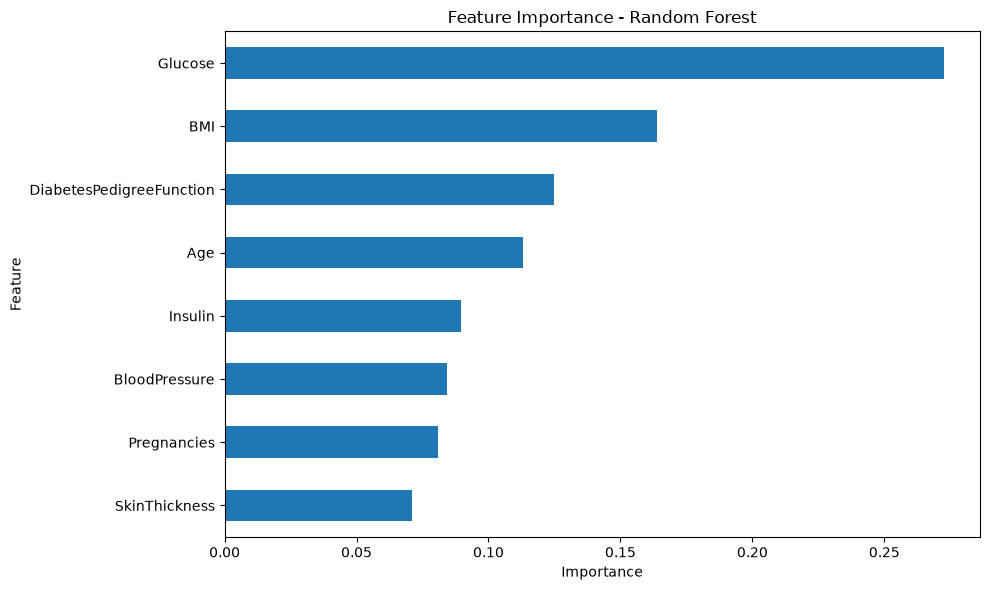

In [72]:
feature_importance.sort_values(
    by="Importance",
    ascending=True
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 6),
    legend=False
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### 6. Conclusion

This project investigated the performance of different machine learning algorithms for diabetes classification using the Pima Indians Diabetes Database. The main objective was to evaluate how different classification methods and class-weighting strategies perform on a dataset with a moderately imbalanced target variable.

During preprocessing, zero values in selected medical measurement features were treated as potentially missing observations and replaced with missing values. Median imputation was then applied within machine learning pipelines to reduce the risk of data leakage during cross-validation.

Three classification algorithms were evaluated: Logistic Regression, Decision Tree, and Random Forest. Both standard and class-weighted versions of each model were developed and compared using stratified five-fold cross-validation.

The results showed that the standard Logistic Regression model achieved the highest mean accuracy (0.788) and precision (0.764), while the Balanced Random Forest model achieved the highest mean F1-score (0.675) and a mean recall of 0.701. The Balanced Logistic Regression model also achieved a high mean ROC-AUC score of 0.844.

These findings demonstrate that model performance depends on the evaluation metric being considered. While standard Logistic Regression performed well in terms of accuracy and precision, class weighting improved recall for Logistic Regression and Random Forest, which may be particularly relevant when identifying positive diabetes cases is an important objective.

Feature importance analysis using the Random Forest model identified Glucose as the most influential feature in the model’s predictions, followed by BMI, DiabetesPedigreeFunction, and Age. However, these importance values describe the model’s internal behavior and should not be interpreted as evidence of causation or clinical significance.

Overall, this project demonstrates the importance of appropriate preprocessing, cross-validation, class-imbalance handling, and the selection of suitable evaluation metrics in machine learning classification tasks.

Finally, the models developed in this project are intended for educational and experimental purposes. They have not been clinically validated and should not be used as medical diagnostic tools.